# 03 · Modelling
Training is done by `python -m src.pipeline` (it also logs every run to MLflow). This notebook loads and discusses the results so it opens instantly.

- Split: **time-based** (train 2023–2024, validation H1-2025, test H2-2025).
- ETA: Linear Regression → Random Forest → XGBoost → LightGBM (sklearn Gradient Boosting stands in if those aren't installed).
- Delay: Logistic Regression → Random Forest → XGBoost → LightGBM, all with class weighting; threshold tuned for F1 on validation; probabilities calibrated on validation.

In [1]:
# Setup: make the project importable from the notebooks/ folder
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
os.environ.setdefault("ARRIVO_OFFLINE", "1")     # use cached/offline enrichment for reproducibility
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

def show(path, width=11):
    """Display a saved figure inline."""
    img = plt.imread(path); h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(width, width * h / w)); ax.imshow(img); ax.axis("off"); plt.show()

In [2]:
# Uncomment to retrain everything from here (takes a few minutes):
# from src.pipeline import run; run(n_trials=30)
import json
card = json.loads((ROOT/'models/model_card.json').read_text())
{k: card[k] for k in ['data_source','trained_at','split','delay_rate','backends']}

{'data_source': 'synthetic', 'trained_at': '2026-10-24 19:29:07', 'split': {'train': ['2023-01-01 05:26:00', '2024-12-31 22:12:00', 9126], 'validation': ['2025-01-01 00:09:00', '2025-06-30 20:40:00', 2824], 'test': ['2025-07-01 05:21:00', '2025-12-30 22:01:00', 2942]}, 'delay_rate': {'train': 0.3853824238439623, 'val': 0.25106232294617564, 'test': 0.3752549286199864}, 'backends': {'xgboost': None, 'lightgbm': None, 'optuna': None, 'mlflow': None}}

## ETA regression – model comparison (hours)

In [3]:
eta = pd.read_csv(ROOT/'reports/metrics/eta_model_comparison.csv')
eta[['model','stage','val_MAE','val_RMSE','val_R2','test_MAE','test_RMSE','test_R2','test_within_10pct_%']].round(3)

,model,stage,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,test_R2,test_within_10pct_%
0,Planner's ETA (no ML),benchmark,5.064,7.057,0.871,5.082,7.402,0.875,37.593
1,LinearRegression,default,3.994,5.617,0.918,4.264,5.934,0.920,44.562
2,RandomForest,default,3.785,5.466,0.923,3.916,5.849,0.922,49.864
3,GradientBoosting (sklearn),default,3.408,4.951,0.936,3.696,5.432,0.933,51.224
4,GradientBoosting (sklearn) (tuned),tuned:random-search,3.410,4.922,0.937,3.673,5.454,0.932,51.462


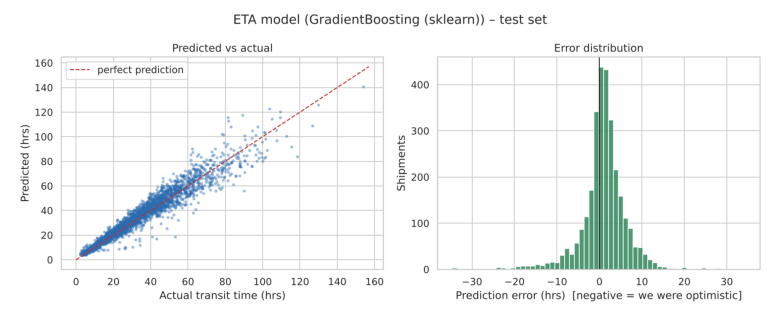

In [4]:
show(ROOT/'reports/figures/eta_test_performance.png')

## Delay classification – model comparison

In [5]:
dl = pd.read_csv(ROOT/'reports/metrics/delay_model_comparison.csv')
dl[['model','stage','val_ROC_AUC','val_F1','test_ROC_AUC','test_PR_AUC','test_F1','test_Precision','test_Recall']].round(3)

,model,stage,val_ROC_AUC,val_F1,test_ROC_AUC,test_PR_AUC,test_F1,test_Precision,test_Recall
0,LogisticRegression,default,0.833,0.615,0.854,0.794,0.724,0.659,0.803
1,RandomForest,default,0.822,0.588,0.837,0.764,0.701,0.665,0.741
2,GradientBoosting (sklearn),default,0.826,0.601,0.843,0.768,0.696,0.576,0.880
3,LogisticRegression (tuned + calibrated),tuned:random-search,0.833,0.616,0.854,0.794,0.724,0.659,0.803


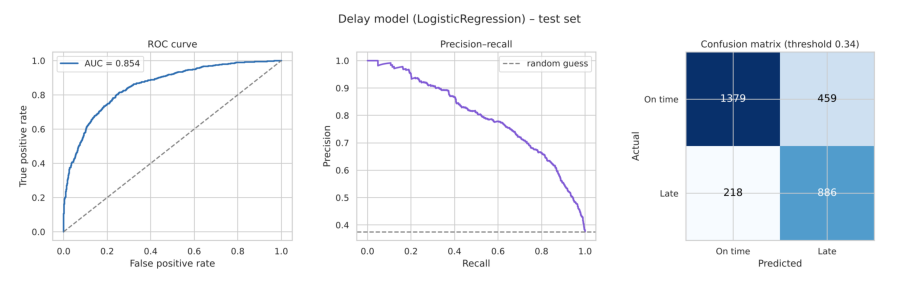

In [6]:
show(ROOT/'reports/figures/delay_test_performance.png', 13)

## Are the risk bands trustworthy? (calibration on the test set)
If the model says ~80% for the High band, about 80% of those shipments should really be late.

In [7]:
pd.read_csv(ROOT/'reports/metrics/risk_band_calibration.csv').round(3)

,band,shipments,mean_predicted_risk,actual_late_rate
0,Low,1635,0.145,0.144
1,Medium,740,0.489,0.534
2,High,567,0.819,0.836


In [8]:
print('ETA final model  :', card['eta_model']['name'], card['eta_model']['params'])
print('Delay final model:', card['delay_model']['name'], card['delay_model']['params'], '| threshold', round(card['delay_model']['threshold'],3))

ETA final model  : GradientBoosting (sklearn) {}
Delay final model: LogisticRegression {'C': 1.3939821771844678} | threshold 0.338


### Discussion points
- Every ML model beats the planner's own ETA; boosted trees win on ETA because the effects are non-linear (rain, hills, breakdown tails).
- For delay risk the simple **logistic regression** is competitive with tree ensembles on this data – with a time split, simpler models often generalise better. We keep whichever wins on *validation*, never on test.
- Validation (Jan–Jun) has fewer monsoon trips than test (Jul–Dec), which is why F1 differs between the two periods – another reason we never tune on the test set.